# OpenAI Agents SDK + MCP

MCP 가이드: https://openai.github.io/openai-agents-python/mcp/

MCP 서버 API 레퍼런스: https://openai.github.io/openai-agents-python/ref/mcp/server/

MCP 서버 코드(math_server.py / weather_server.py)는 원본 그대로이고, 클라이언트만 OpenAI Agents SDK로 교체했습니다.


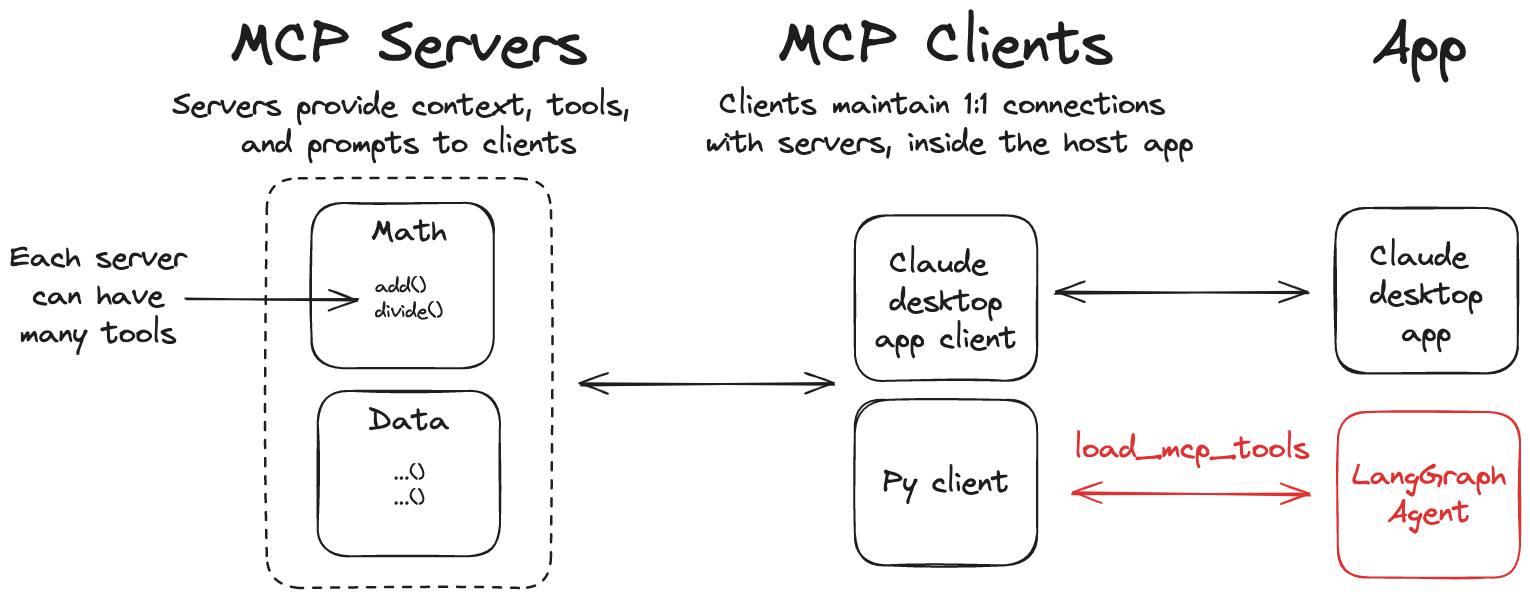

# 세팅

In [ ]:
! uv pip install openai-agents

In [ ]:
! uv pip install pywin32

In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("OPENAI API Key가 설정되었습니다.")

OPENAI API Key가 설정되었습니다.


OPENAI_API_KEY는 Agents SDK가 환경 변수에서 자동으로 읽습니다.

# [예제1] MCP server  & MCP Client

##   create an MCP server 

can add and multiply numbers.

In [ ]:
# math_server.py
# MCP 서버 라이브러리에서 FastMCP 클래스를 가져옴
from mcp.server.fastmcp import FastMCP

# "Math"라는 이름의 MCP 서버 인스턴스를 생성
mcp = FastMCP("Math")

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def add(a: int, b: int) -> int:
    """Add two numbers"""  # 두 숫자를 더하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 더한 결과를 반환
    return a + b

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def multiply(a: int, b: int) -> int:
    """Multiply two numbers"""  # 두 숫자를 곱하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 곱한 결과를 반환
    return a * b

# 이 파일이 직접 실행될 때만 아래 코드를 실행
if __name__ == "__main__":
    # 서버 시작 안내 메시지를 콘솔에 출력
    print("MCP server started and waiting for clients...")
    # streamable-http 전송 방식으로 MCP 서버를 실행 (기본적으로 http://localhost:8000/mcp 에서 대기)
    mcp.run(transport="streamable-http")

터미날에서 math_server.py 실행



In [ ]:
! uv run math_server.py

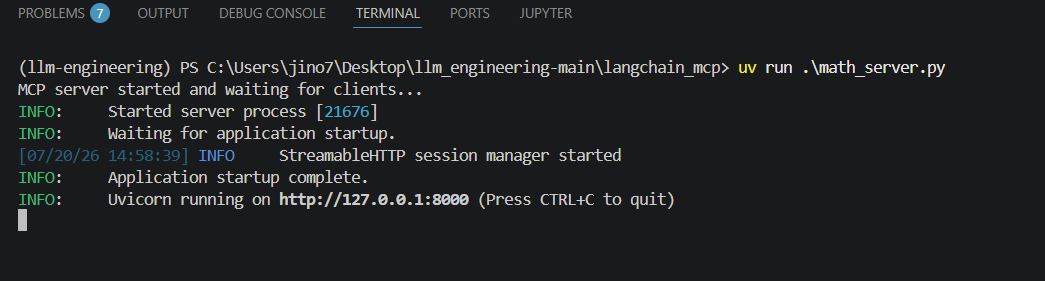

## MCP Client

`MCPServerStreamableHttp` 로 MCP 서버에 연결하고, 그 서버 객체를 `Agent(mcp_servers=[...])` 에 넘깁니다.

`client.get_tools()` 처럼 도구를 미리 뽑아 오지 않습니다. 서버 객체를 넘기면 실행할 때 SDK가 도구 목록을 가져옵니다.

`async with` 블록을 벗어나면 연결이 닫히므로 `Runner.run()` 은 같은 블록 안에서 호출해야 합니다.

In [2]:
# 에이전트 정의 클래스와 실행기를 가져옴
from agents import Agent, Runner
# streamable-http 방식 MCP 서버에 연결하는 클래스를 가져옴
from agents.mcp import MCPServerStreamableHttp

# math_server.py(포트 8000)에 연결
async with MCPServerStreamableHttp(
    name="math",
    params={"url": "http://localhost:8000/mcp"},
) as server:
    # MCP 서버의 도구를 사용하는 에이전트를 생성
    agent = Agent(
        name="Assistant",
        instructions="Use the MCP tools to answer the questions.",
        model="gpt-5-mini",
        mcp_servers=[server],
    )
    # 질문을 전달하고 실행이 끝날 때까지 대기
    result = await Runner.run(agent, "what's (3 + 5) x 12?")

# 최종 답변을 출력
print(result.final_output)


96


# [예제2] Multiple MCP Servers

https://openai.github.io/openai-agents-python/mcp/#5-mcp-server-manager

# 서버 세팅

##   1번 서버

can add and multiply numbers.

In [ ]:
# math_server.py
# MCP 서버 라이브러리에서 FastMCP 클래스를 가져옴
from mcp.server.fastmcp import FastMCP

# "Math"라는 이름의 MCP 서버 인스턴스를 생성
mcp = FastMCP("Math")

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def add(a: int, b: int) -> int:
    """Add two numbers"""  # 두 숫자를 더하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 더한 결과를 반환
    return a + b

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def multiply(a: int, b: int) -> int:
    """Multiply two numbers"""  # 두 숫자를 곱하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 곱한 결과를 반환
    return a * b

# 이 파일이 직접 실행될 때만 아래 코드를 실행
if __name__ == "__main__":
    # 서버 시작 안내 메시지를 콘솔에 출력
    print("MCP server started and waiting for clients...")
    # streamable-http 전송 방식으로 MCP 서버를 실행 (기본적으로 http://localhost:8000/mcp 에서 대기)
    mcp.run(transport="streamable-http")

터미날에서 math_server.py 실행



In [ ]:
! uv run math_server.py

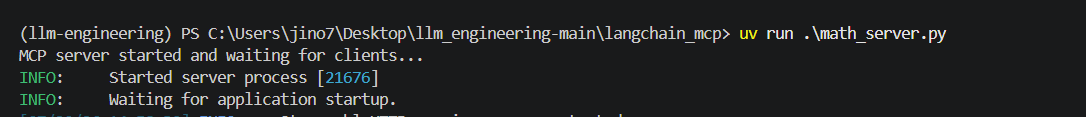

## 2번 서버

In [ ]:
# weather_server.py
# 타입 힌트를 위한 List를 가져옴
from typing import List
# MCP 서버 라이브러리에서 FastMCP 클래스를 가져옴
from mcp.server.fastmcp import FastMCP

# "Weather"라는 이름의 MCP 서버 인스턴스를 생성하고, 서버 포트를 8001로 지정
mcp = FastMCP("Weather", port=8001)

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
async def get_weather(location: str) -> str:
    """Get weather for location."""  # 지정한 위치의 날씨를 조회하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 고정된 날씨 문자열을 반환 (실제 API 호출 없이 테스트용 응답)
    return "It's always sunny in New York"

# 이 파일이 직접 실행될 때만 아래 코드를 실행
if __name__ == "__main__":
    # http 전송 방식으로 MCP 서버를 실행 (포트 8001에서 대기)
     mcp.run(transport="streamable-http")

서버 실행

In [ ]:
! uv run weather_server.py 

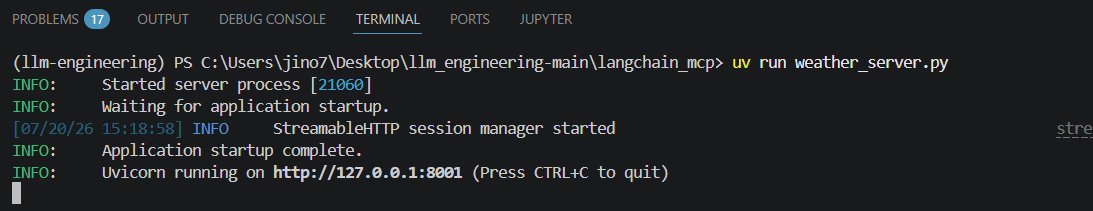

# MCP 클라이언트 

서버가 여러 개일 때는 `MCPServerManager` 로 한 번에 연결하고, 연결에 성공한 서버만 `manager.active_servers` 로 받습니다.

In [3]:
# 에이전트 정의 클래스와 실행기를 가져옴
from agents import Agent, Runner
# 여러 MCP 서버를 한꺼번에 관리하는 매니저와 streamable-http 서버 클래스를 가져옴
from agents.mcp import MCPServerManager, MCPServerStreamableHttp

# 연결할 MCP 서버 목록 (math는 8000, weather는 8001에서 실행 중이어야 함)
servers = [
    MCPServerStreamableHttp(name="math", params={"url": "http://localhost:8000/mcp"}),
    MCPServerStreamableHttp(name="weather", params={"url": "http://localhost:8001/mcp"}),
]

# 매니저가 두 서버에 연결하고, 블록을 벗어날 때 정리함
async with MCPServerManager(servers) as manager:
    agent = Agent(
        name="Assistant",
        instructions="Use the MCP tools to answer the questions.",
        model="gpt-5-mini",
        # active_servers: 연결에 성공한 서버 목록
        mcp_servers=manager.active_servers,
    )
    # math 서버 도구를 사용하는 질문
    math_response = await Runner.run(agent, "what's (3 + 5) x 12?")
    # weather 서버 도구를 사용하는 질문
    weather_response = await Runner.run(agent, "what is the weather in nyc?")

# 각 질문의 최종 답변을 출력
print(math_response.final_output)
print(weather_response.final_output)


(3 + 5) × 12 = 96
It's always sunny in New York.


## 대안: 중첩 `async with`

설치된 `openai-agents` 버전에 `MCPServerManager` 가 없어 `ImportError` 가 나면 아래 방식을 쓰면 됩니다.
(어느 버전부터 추가됐는지는 확인하지 못했습니다.)

In [4]:
# 에이전트 정의 클래스와 실행기를 가져옴
from agents import Agent, Runner
# streamable-http 방식 MCP 서버에 연결하는 클래스를 가져옴
from agents.mcp import MCPServerStreamableHttp

# math 서버에 연결
async with MCPServerStreamableHttp(name="math", params={"url": "http://localhost:8000/mcp"}) as math_server:
    # weather 서버에 연결 (math 연결을 유지한 채 중첩)
    async with MCPServerStreamableHttp(name="weather", params={"url": "http://localhost:8001/mcp"}) as weather_server:
        agent = Agent(
            name="Assistant",
            instructions="Use the MCP tools to answer the questions.",
            model="gpt-5-mini",
            # 두 MCP 서버를 함께 전달
            mcp_servers=[math_server, weather_server],
        )
        math_response = await Runner.run(agent, "what's (3 + 5) x 12?")
        weather_response = await Runner.run(agent, "what is the weather in nyc?")

# 각 질문의 최종 답변을 출력
print(math_response.final_output)
print(weather_response.final_output)


(3 + 5) × 12 = 96
It's always sunny in New York.


# 참고: LangChain 어댑터와 달라지는 점

| 항목 | langchain-mcp-adapters | OpenAI Agents SDK |
| --- | --- | --- |
| 서버 연결 | `MultiServerMCPClient(dict)` | 서버마다 `MCPServerStreamableHttp` 객체 |
| 도구 획득 | `tools = await client.get_tools()` | 서버 객체를 `mcp_servers=` 에 전달 |
| 연결 수명 | 호출 시점마다 세션을 열고 닫음 | `async with` 블록 동안 세션 유지 |
| 에이전트 생성 | `create_agent("openai:gpt-5-mini", tools)` | `Agent(model="gpt-5-mini", mcp_servers=[...])` |
| 실행 | `await agent.ainvoke({"messages": ...})` | `await Runner.run(agent, "...")` |
| 결과 | `response["messages"]` 리스트 | `result.final_output` |

중간 과정(도구 호출, 도구 결과)은 `result.new_items` 에 들어 있습니다.

## 주의 / 논란이 될 수 있는 부분

**1. 노트북에서의 `async with`**

IPython은 셀 상단의 `await` / `async with` 를 지원하지만, 셀이 끝나면 컨텍스트 매니저가 닫히고 MCP 세션도 끊깁니다. `Runner.run()` 은 서버를 연 셀 안에 함께 있어야 하고, 셀을 나눠 `agent` 만 재사용하면 연결이 끊긴 상태가 됩니다.

**2. 위 코드에서 뺀 옵션들**

- `cache_tools_list=True` : 기본값 `False` 라 매 실행마다 `list_tools()` 를 호출합니다. 로컬 서버에서는 부담이 작지만 원격 서버에서는 왕복 지연이 붙습니다. 도구 정의가 자주 바뀌지 않을 때만 켜라는 것이 공식 문서 권고이고, 개발 중 서버 도구를 고치는 상황에서는 캐시가 오히려 방해가 됩니다.
- `include_server_in_tool_names=True` : 서버마다 같은 이름의 도구가 있을 때 충돌을 막는 옵션입니다. math / weather는 이름이 겹치지 않아 뺐습니다. 켜면 모델에 노출되는 도구 이름이 바뀝니다.
- `ModelSettings(tool_choice="required")` : 공식 예제에는 있지만 뺐습니다. 도구를 반드시 호출하게 강제하므로 도구가 필요 없는 질문에서도 억지로 부르게 됩니다.

**3. 호스티드 MCP(`HostedMCPTool`)를 쓰지 않은 이유**

OpenAI Responses API가 서버에 직접 접속하는 방식이라 서버가 공개 주소로 접근 가능해야 합니다. 이 노트북의 서버는 `localhost` 라 해당되지 않습니다.